# Unit 17 — Data Mining for Business Processes

A practical bridge from EDA to business-oriented pattern discovery.

## Learning Objectives
- Explain data mining and distinguish it from EDA.
- Identify common business data-mining tasks.
- Detect and investigate anomalies.
- Discover simple frequency and relationship patterns.
- Explain segmentation and market-basket concepts.
- Translate mined patterns into business recommendations.

## Prerequisites
- Python basics
- NumPy and Pandas
- Data cleaning and EDA
- Basic Matplotlib

## Class Delivery
Approx. 60 minutes. Keep the focus on reasoning and interpretation rather than new libraries.

> **Teaching pattern:** explain the concept → demonstrate → interpret → practise → connect to a business decision.

## 1. Where Data Mining Fits

You already know the workflow:

`raw data → cleaning → transformation → EDA → visualisation`

Data mining goes one step further:

`data → discover hidden patterns, unusual behaviour, relationships and useful groups → business action`

### EDA vs Data Mining

| EDA | Data Mining |
|---|---|
| Understand what the data looks like | Discover useful patterns hidden in the data |
| Summarise and visualise | Search for structures and relationships |
| Ask: “What is here?” | Ask: “What useful pattern can we discover?” |
| Often broad and exploratory | Often focused on a business question |

The important point is that **EDA describes and explores**, while **data mining actively searches for useful structure or relationships**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (10, 5)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.3
Pandas: 3.0.5


## 2. Business Questions for Data Mining

Typical questions include:

- Which transactions look unusual?
- Which products or categories are frequently purchased?
- Which regions perform similarly?
- Which customers behave similarly?
- Which combinations of variables are associated with high-value transactions?
- Which patterns could improve marketing, inventory, fraud detection or operations?

The Unit 17 specification explicitly identifies data mining for finding **anomalies, clusters, patterns and relationships between datasets**.

## 3. Data Mining Workflow

```text
Business Question
      ↓
Select Relevant Data
      ↓
Prepare / Validate Data
      ↓
Choose Mining Technique
      ↓
Find Pattern
      ↓
Check Reliability / Context
      ↓
Interpret in Business Terms
      ↓
Recommendation
```

A pattern is **not automatically an insight**. Students must ask why it matters and what decision it could influence.

## 4. Create a Retail Transaction Dataset

In [2]:
rng = np.random.default_rng(42)

n = 600
sales = pd.DataFrame({
    "transaction_id": np.arange(10001, 10001+n),
    "customer_id": rng.integers(1, 151, n),
    "region": rng.choice(["North", "South", "East", "West"], n),
    "category": rng.choice(["Electronics", "Office", "Home", "Grocery"], n,
                           p=[0.25, 0.30, 0.20, 0.25]),
    "quantity": rng.integers(1, 8, n),
    "unit_price": rng.choice([50, 75, 120, 250, 500, 900, 1500], n),
    "discount": rng.choice([0, 0.05, 0.10, 0.15], n,
                           p=[0.45, 0.30, 0.20, 0.05]),
    "payment": rng.choice(["UPI", "Card", "Cash"], n)
})

sales["revenue"] = sales["quantity"] * sales["unit_price"] * (1 - sales["discount"])
sales.head()

,transaction_id,customer_id,region,category,quantity,unit_price,discount,payment,revenue
0,10001,14,East,Office,1,900,0.05,Card,855.0
1,10002,117,West,Grocery,4,500,0.05,Card,1900.0
2,10003,99,East,Grocery,6,1500,0.00,UPI,9000.0
3,10004,66,North,Home,4,1500,0.05,Cash,5700.0
4,10005,65,West,Grocery,3,500,0.05,Cash,1425.0


## 5. Mining Task — Frequency Patterns

A simple form of pattern discovery is frequency analysis.

Examples:

- most common region
- most common category
- most common payment method
- most common customer group

Frequency alone is not enough. We should connect it to **revenue, profitability, customer behaviour or another business outcome**.

In [3]:
for column in ["region", "category", "payment"]:
    print(f"\n--- {column.upper()} ---")
    print(sales[column].value_counts())


--- REGION ---
region
East     169
West     148
North    146
South    137
Name: count, dtype: int64

--- CATEGORY ---
category
Office         175
Grocery        161
Electronics    154
Home           110
Name: count, dtype: int64

--- PAYMENT ---
payment
Cash    212
Card    208
UPI     180
Name: count, dtype: int64


In [4]:
category_summary = (
    sales.groupby("category")
         .agg(
             transactions=("transaction_id", "count"),
             total_revenue=("revenue", "sum"),
             average_transaction=("revenue", "mean")
         )
         .sort_values("total_revenue", ascending=False)
)
category_summary

,transactions,total_revenue,average_transaction
category,,,
Office,175,331169.0,1892.394286
Grocery,161,313522.0,1947.341615
Electronics,154,277916.5,1804.652597
Home,110,223046.0,2027.690909


### Interpretation

Students should move beyond:

> “Electronics occurred 154 times.”

towards:

> “Electronics has the largest transaction count and also produces the greatest total revenue, so it is strategically important to the business.”

The second statement is business insight.

## 6. Anomaly Detection

### What is an anomaly?

An anomaly is an observation that behaves differently from the normal pattern.

Examples:

- unusually large transaction
- unusually high quantity
- unusually low or high price
- abnormal machine reading
- suspicious login behaviour

An anomaly is **a signal for investigation**, not proof of an error or fraud.

### 6.1 IQR-Based Detection

For a numerical variable:

- Q1 = 25th percentile
- Q3 = 75th percentile
- IQR = Q3 − Q1
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Observations outside the bounds are candidates for investigation.

In [5]:
q1 = sales["revenue"].quantile(0.25)
q3 = sales["revenue"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

sales["revenue_anomaly"] = ~sales["revenue"].between(lower, upper)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower)
print("Upper bound:", upper)

sales.loc[sales["revenue_anomaly"]].sort_values("revenue", ascending=False).head(10)

Q1: 285.0
Q3: 2700.0
IQR: 2415.0
Lower bound: -3337.5
Upper bound: 6322.5


,transaction_id,customer_id,region,category,quantity,unit_price,discount,payment,revenue,revenue_anomaly
210,10211,40,North,Electronics,7,1500,0.00,Cash,10500.0,True
157,10158,84,South,Grocery,7,1500,0.00,Card,10500.0,True
427,10428,121,South,Office,7,1500,0.00,Cash,10500.0,True
505,10506,69,North,Grocery,7,1500,0.00,Cash,10500.0,True
312,10313,18,South,Grocery,7,1500,0.00,Cash,10500.0,True
552,10553,125,South,Electronics,7,1500,0.00,UPI,10500.0,True
309,10310,17,North,Office,7,1500,0.00,UPI,10500.0,True
45,10046,146,South,Grocery,7,1500,0.05,Cash,9975.0,True
354,10355,146,West,Grocery,7,1500,0.05,Cash,9975.0,True
269,10270,89,North,Electronics,7,1500,0.05,Cash,9975.0,True


### Teaching Shift

Students already know how to calculate outliers. Now change the question:

**Statistics:** Which observations are unusual?

**Business data mining:** Why are they unusual, and what should the business investigate?

In [6]:
anomaly_summary = (
    sales.loc[sales["revenue_anomaly"]]
         .groupby("region")
         .size()
         .sort_values(ascending=False)
)

anomaly_summary

region
East     12
North     9
South     9
West      4
dtype: int64

### 6.2 Context Matters

An unusual value may be normal for a particular group.

For example:

- ₹500,000 may be unusual in a small retail shop.
- ₹500,000 may be normal in a wholesale business.

Therefore, students should compare observations with the **correct peer group** when appropriate.

In [7]:
region_stats = (
    sales.groupby("region")["revenue"]
         .agg(["count", "mean", "median", "max"])
         .sort_values("max", ascending=False)
)
region_stats

,count,mean,median,max
region,,,,
North,146,1962.316781,847.500,10500.0
South,137,2050.961679,750.000,10500.0
West,148,1506.148649,489.375,9975.0
East,169,2102.150888,900.000,9450.0


## 7. Relationship Discovery

Data mining can reveal relationships between variables or categories.

Examples:

- discount and quantity
- category and revenue
- region and average order value
- customer type and frequency
- payment method and transaction size

Remember:

> **Relationship does not automatically mean causation.**

In [8]:
relationship = (
    sales.groupby("discount")
         .agg(
             average_quantity=("quantity", "mean"),
             average_revenue=("revenue", "mean"),
             transactions=("transaction_id", "count")
         )
         .reset_index()
)

relationship

,discount,average_quantity,average_revenue,transactions
0,0.00,3.909722,1944.947917,288
1,0.05,4.065868,1878.980539,167
2,0.10,4.123894,1862.960177,113
3,0.15,4.406250,1912.632812,32


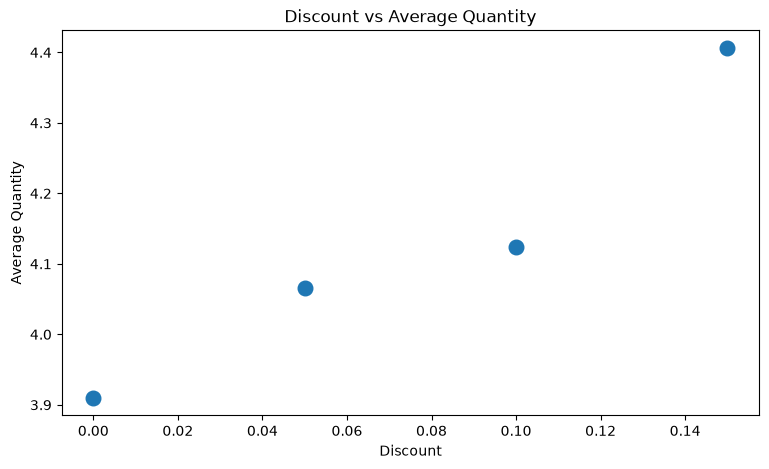

In [9]:
plt.figure(figsize=(9, 5))
plt.scatter(relationship["discount"], relationship["average_quantity"], s=110)
plt.xlabel("Discount")
plt.ylabel("Average Quantity")
plt.title("Discount vs Average Quantity")
plt.show()

## 8. Customer Behaviour and Simple Segmentation

A common business mining task is identifying groups of customers by behaviour.

Useful measures:

- **Recency** — how recently a customer purchased
- **Frequency** — how often a customer purchased
- **Monetary value** — how much a customer spent

For Unit 17, focus on the idea of segmentation rather than implementing machine-learning clustering. Full clustering algorithms can be taught in the next unit.

In [10]:
customer_summary = (
    sales.groupby("customer_id")
         .agg(
             purchase_count=("transaction_id", "count"),
             total_spend=("revenue", "sum"),
             average_order_value=("revenue", "mean")
         )
         .reset_index()
)

customer_summary["customer_value_band"] = pd.cut(
    customer_summary["total_spend"],
    bins=[
        -np.inf,
        customer_summary["total_spend"].quantile(0.33),
        customer_summary["total_spend"].quantile(0.66),
        np.inf
    ],
    labels=["Low", "Medium", "High"]
)

customer_summary.head(10)

,customer_id,purchase_count,total_spend,average_order_value,customer_value_band
0,1,2,2544.0,1272.000000,Low
1,2,3,2650.0,883.333333,Low
2,3,4,6650.0,1662.500000,Medium
3,4,7,11839.0,1691.285714,High
4,5,2,6935.0,3467.500000,Medium
5,6,3,5450.0,1816.666667,Medium
6,7,5,4685.0,937.000000,Medium
7,8,2,1560.0,780.000000,Low
8,9,3,4045.0,1348.333333,Medium
9,10,3,22950.0,7650.000000,High


In [11]:
customer_summary["customer_value_band"].value_counts().sort_index()

customer_value_band
Low       49
Medium    49
High      51
Name: count, dtype: int64

### Business interpretation

A useful statement is:

> High-value customers contribute more revenue per customer, so retention and loyalty activity may deserve priority for that group.

Students should always connect the segment to a potential **business action**.

## 9. Simple Market-Basket / Co-Occurrence Concept

Another classic data-mining problem is:

> Which products or categories tend to occur together?

### Key ideas

- **Support:** how frequently an item/set appears.
- **Confidence:** how often B appears when A appears.
- **Lift:** how much stronger the relationship is than a baseline expectation.

For this unit, students should understand the concepts and business meaning. A full association-rule implementation can be left to a more specialised analytics/ML unit.

In [12]:
transactions = [
    {"Bread", "Butter", "Milk"},
    {"Bread", "Butter"},
    {"Bread", "Milk"},
    {"Bread", "Butter", "Jam"},
    {"Milk", "Cookies"},
    {"Bread", "Butter", "Milk"},
    {"Bread", "Jam"},
    {"Butter", "Milk"},
]

def support(itemset, transactions):
    itemset = set(itemset)
    return sum(itemset.issubset(t) for t in transactions) / len(transactions)

candidate_pairs = [
    ("Bread", "Butter"),
    ("Bread", "Milk"),
    ("Butter", "Milk"),
    ("Bread", "Jam"),
]

for pair in candidate_pairs:
    print(pair, "support =", round(support(pair, transactions), 3))

('Bread', 'Butter') support = 0.5
('Bread', 'Milk') support = 0.375
('Butter', 'Milk') support = 0.375
('Bread', 'Jam') support = 0.25


## 10. Business Mining Exercise

Use the `sales` dataset to answer:

1. Which category generates the most revenue?
2. Which region has the highest average transaction value?
3. Are there unusual transactions?
4. Which customers appear most valuable?
5. What relationship deserves further investigation?
6. What would you recommend to management?

### Required response format

**Finding → Evidence → Interpretation → Recommendation**

In [13]:
# Student workspace
# Write your own analysis below.

# Example:
# answer = sales.groupby("region")["revenue"].sum().sort_values(ascending=False)
# answer

## 11. Common Data-Mining Mistakes

- Treating every anomaly as an error.
- Confusing association with causation.
- Ignoring the size of the group being compared.
- Reporting a pattern without checking data quality.
- Finding a technically interesting pattern that has no business value.
- Making a recommendation without evidence.
- Changing the analysis question after seeing the result without documenting it.

## 12. Mini Project — “Find Something the Manager Should Know”

Choose a business area:

- retail
- banking
- telecom
- logistics
- education
- manufacturing

Write:

1. one business question
2. the data required
3. the data-mining method
4. expected pattern
5. business action

Then demonstrate it with the `sales` dataset or another classroom dataset.

## 13. Summary

You should now be able to explain that data mining is about **discovering useful patterns, anomalies, relationships and segments and turning those discoveries into meaningful business information**.

Next: **Web Scraping and APIs — how data can be collected from external sources.**